In [9]:
import pandas as pd
import matplotlib as plt
from pathlib import Path
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio

In [3]:
DATA_DIR = Path("../data") 
AUDIO_DIR = DATA_DIR / "cremad"


EMOTIONS = {
    "ANG": "anger",
    "DIS": "disgust",
    "FEA": "fear",
    "HAP": "happiness",
    "NEU": "neutral",
    "SAD": "sadness",
}

rows = [] 
for file in sorted(AUDIO_DIR.glob("*.wav")):
    speaker, sentence, emotion_code, intensity = file.stem.split("_")
    info = sf.info(file)

    rows.append({
        "path": str(file.relative_to(DATA_DIR)),
        "speaker": int(speaker),
        "sentence": sentence,
        "emotion": EMOTIONS[emotion_code],
        "intensity": intensity,
        "duration": info.duration,
        "sample_rate": info.samplerate,
    })

df = pd.DataFrame(rows)
df

,path,speaker,sentence,emotion,intensity,duration,sample_rate
0,cremad/1001_DFA_ANG_XX.wav,1001,DFA,anger,XX,2.275562,16000
1,cremad/1001_DFA_DIS_XX.wav,1001,DFA,disgust,XX,2.335688,16000
2,cremad/1001_DFA_FEA_XX.wav,1001,DFA,fear,XX,2.168813,16000
3,cremad/1001_DFA_HAP_XX.wav,1001,DFA,happiness,XX,1.868500,16000
4,cremad/1001_DFA_NEU_XX.wav,1001,DFA,neutral,XX,2.035375,16000
...,...,...,...,...,...,...,...
7437,cremad/1091_WSI_DIS_XX.wav,1091,WSI,disgust,XX,2.502500,16000
7438,cremad/1091_WSI_FEA_XX.wav,1091,WSI,fear,XX,2.502500,16000
7439,cremad/1091_WSI_HAP_XX.wav,1091,WSI,happiness,XX,2.168813,16000
7440,cremad/1091_WSI_NEU_XX.wav,1091,WSI,neutral,XX,2.335688,16000


<Axes: title={'center': 'Emotion Distribution'}, xlabel='emotion'>

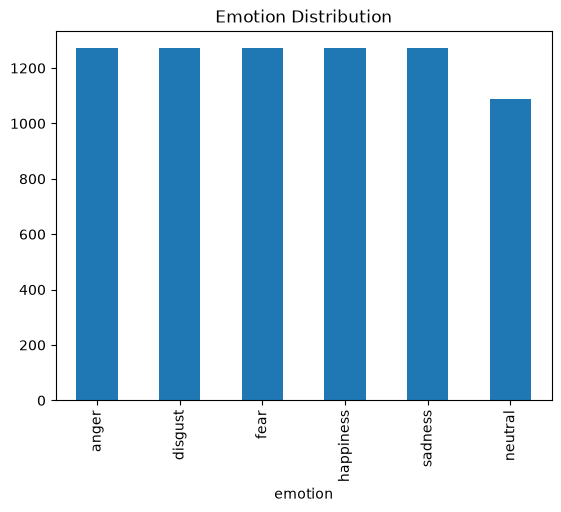

In [4]:
df.value_counts("emotion").plot(kind="bar", title="Emotion Distribution")

<Axes: title={'center': 'Intensity Distribution'}, xlabel='intensity'>

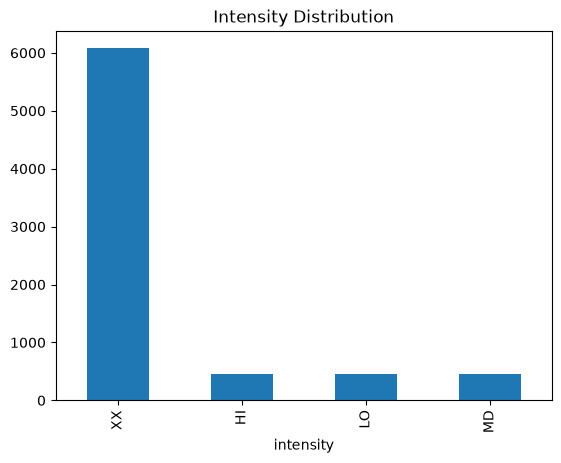

In [5]:
df.value_counts("intensity").plot(kind="bar", title="Intensity Distribution")

<Axes: title={'center': 'Duration Distribution'}, xlabel='Duration in seconds', ylabel='Count'>

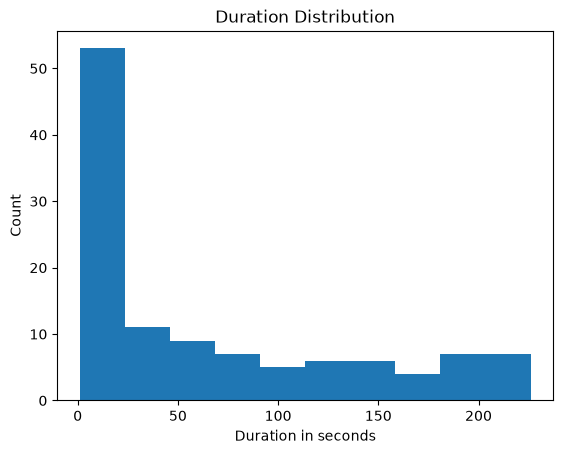

In [ ]:
df.value_counts("duration").plot(kind="hist", title="Duration Distribution", xlabel="Duration ", ylabel="Count")

In [ ]:


longest = df.sort_values("duration", ascending=False).iloc[0]
print(longest["path"], longest["emotion"], longest["duration"])
Audio(DATA_DIR / longest["path"])

cremad/1004_IEO_SAD_HI.wav sadness 5.005


vorher 5.00 s, nachher 5.00 s


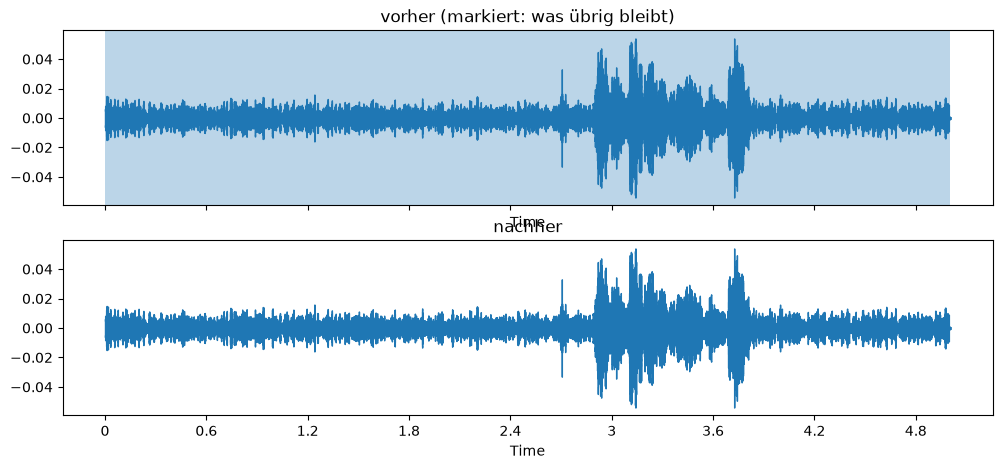

In [10]:
wave, sr = librosa.load(DATA_DIR / longest["path"], sr=None)
trimmed, (start, end) = librosa.effects.trim(wave, top_db=30)

print(f"vorher {len(wave) / sr:.2f} s, nachher {len(trimmed) / sr:.2f} s")

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
librosa.display.waveshow(wave, sr=sr, ax=axes[0])
axes[0].axvspan(start / sr, end / sr, alpha=0.3)     # markiert den Teil, der bleibt
axes[0].set_title("vorher (markiert: was übrig bleibt)")
librosa.display.waveshow(trimmed, sr=sr, ax=axes[1])
axes[1].set_title("nachher")
plt.show()

Audio(trimmed, rate=sr)

In [ ]:
import numpy as np
import librosa


def trim_silence(wave, sr, margin_db=10, frame_ms=25, hop_ms=10, pad_ms=100):
    """Schneidet Stille am Anfang und Ende ab, auch wenn im Hintergrund Rauschen ist.

    Statt mit der lautesten Stelle (wie librosa.effects.trim) wird jedes Fenster
    mit dem Rauschpegel des Clips verglichen. Sprache ist, was mindestens
    margin_db Dezibel lauter ist als das Rauschen.
    """
    frame = int(sr * frame_ms / 1000)
    hop = int(sr * hop_ms / 1000)

   
    rms = librosa.feature.rms(y=wave, frame_length=frame, hop_length=hop)[0]
    db = librosa.amplitude_to_db(rms, ref=np.max)

 
    noise_floor = np.percentile(db, 10)

   
    speech = db > noise_floor + margin_db
    if not speech.any():
        return wave, speech

   
    first, last = np.flatnonzero(speech)[[0, -1]]
    pad = int(sr * pad_ms / 1000)
    start = max(first * hop - pad, 0)
    end = min(last * hop + frame + pad, len(wave))
    return wave[start:end], speech

In [13]:
wave, sr = librosa.load(DATA_DIR / "cremad/1080_IEO_SAD_LO.wav", sr=None)
trimmed, speech = trim_silence(wave, sr)
Audio(trimmed, rate=sr)

In [ ]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, display


def show_trim(path, margin_db=10, pad_ms=100):
    wave, sr = librosa.load(path, sr=None)
    trimmed, speech = trim_silence(wave, sr, margin_db=margin_db, pad_ms=pad_ms)

    hop = int(sr * 0.010)
    rms = librosa.feature.rms(y=wave, frame_length=int(sr * 0.025), hop_length=hop)[0]
    db = librosa.amplitude_to_db(rms, ref=np.max)
    noise_floor = np.percentile(db, 10)
    times = librosa.frames_to_time(np.arange(len(db)), sr=sr, hop_length=hop)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    librosa.display.waveshow(wave, sr=sr, ax=ax1, alpha=0.6)
    ax1.set_title(f"{path.name}: {len(wave) / sr:.2f} s -> {len(trimmed) / sr:.2f} s")

    ax2.plot(times, db, label="Lautstärke pro Fenster")
    ax2.axhline(noise_floor, color="gray", linestyle="--", label="Rauschpegel")
    ax2.axhline(noise_floor + margin_db, color="red", linestyle="--", label="Schwelle")
    ax2.fill_between(times, db.min(), db.max(), where=speech, alpha=0.2, label="als Sprache erkannt")
    ax2.set_xlabel("Zeit (s)")
    ax2.set_ylabel("dB unter der Spitze")
    ax2.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

    print("Original:")
    display(Audio(wave, rate=sr))
    print("Gekürzt:")
    display(Audio(trimmed, rate=sr))

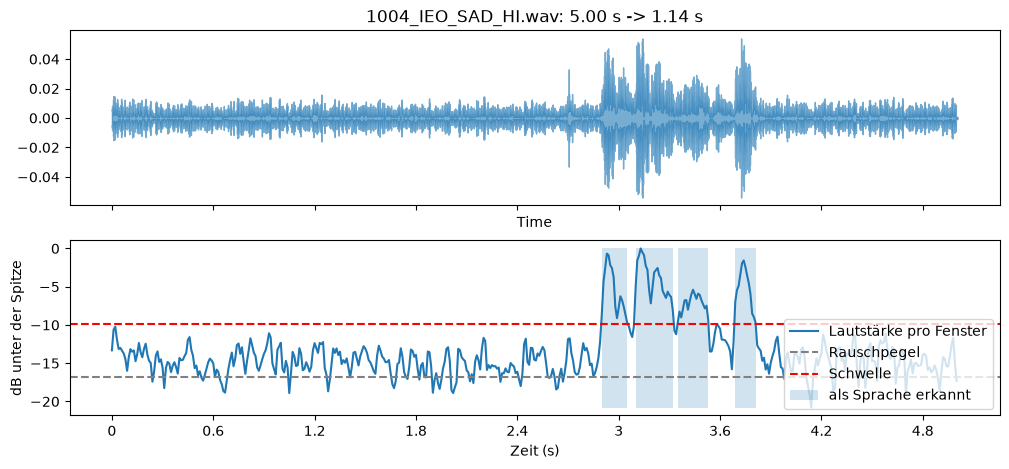

Original:


Gekürzt:


In [28]:
show_trim(DATA_DIR / "cremad/1004_IEO_SAD_HI.wav",margin_db=7)

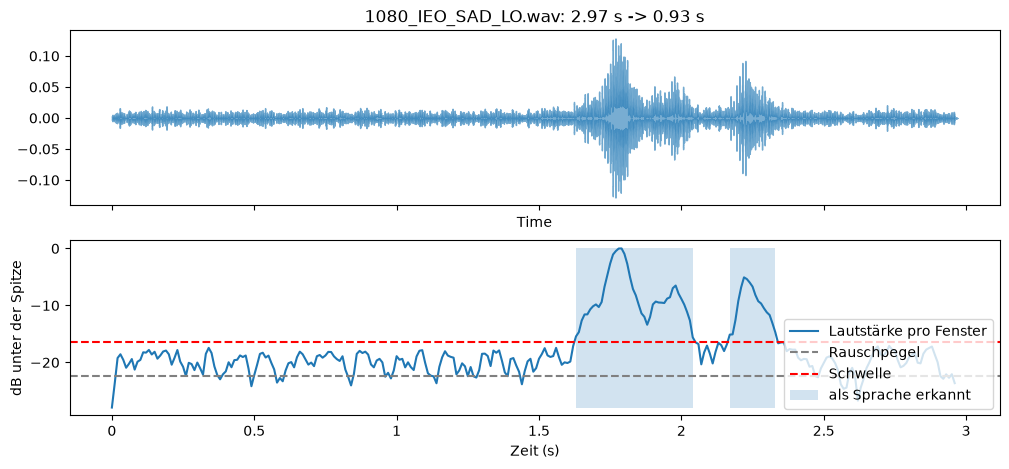

Original:


Gekürzt:


In [16]:
show_trim(DATA_DIR / "cremad/1080_IEO_SAD_LO.wav", margin_db=6)

DFA


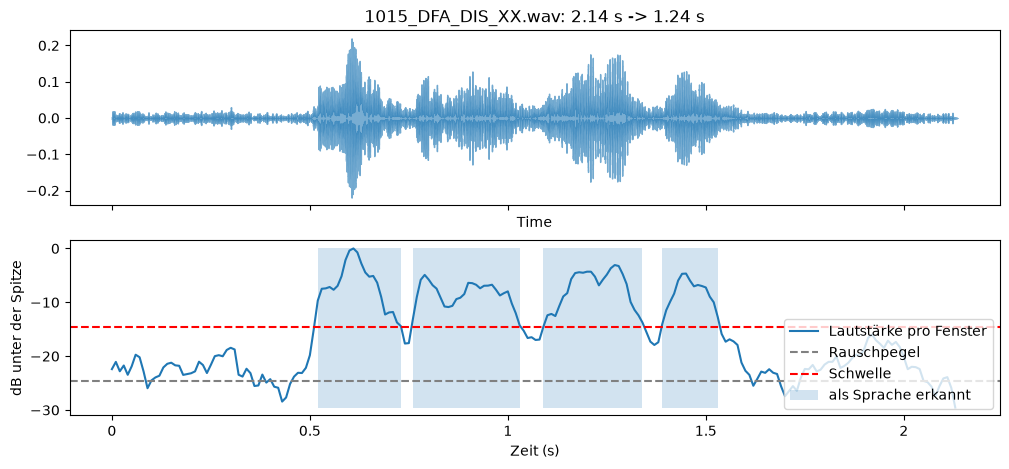

Original:


Gekürzt:


IEO


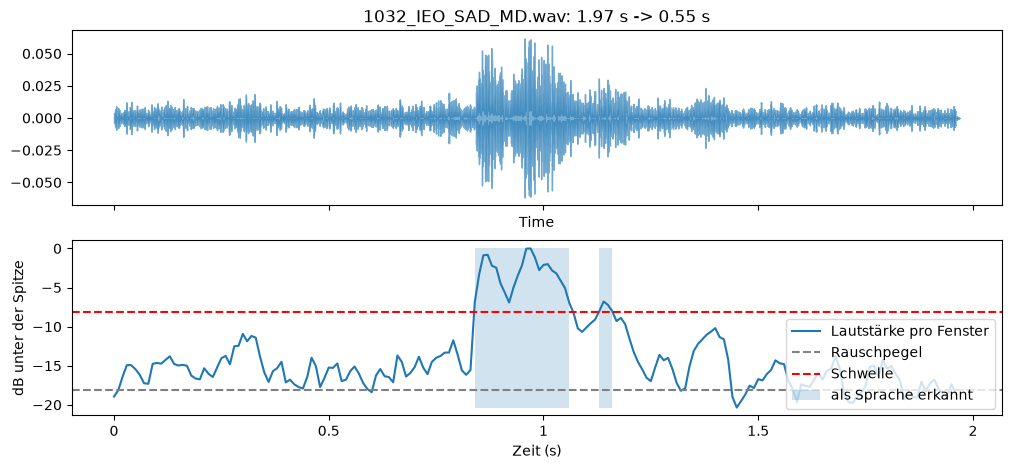

Original:


Gekürzt:


IOM


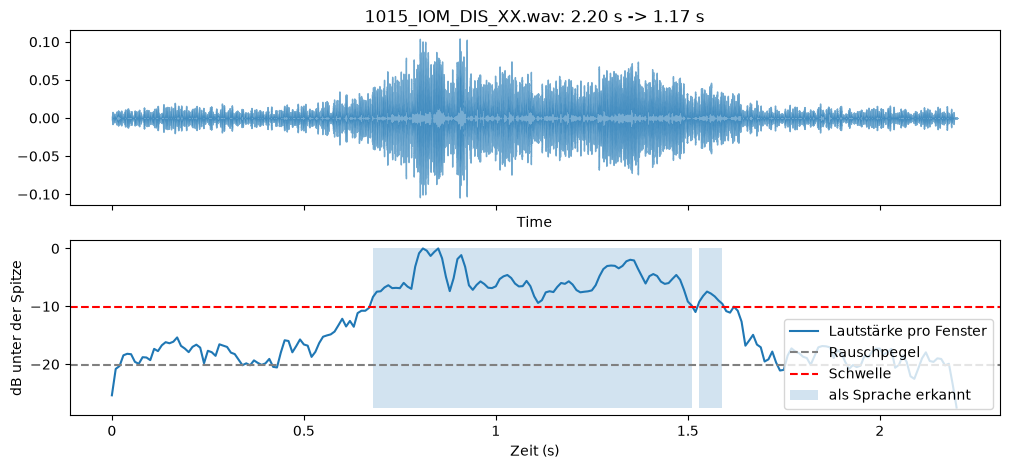

Original:


Gekürzt:


ITH


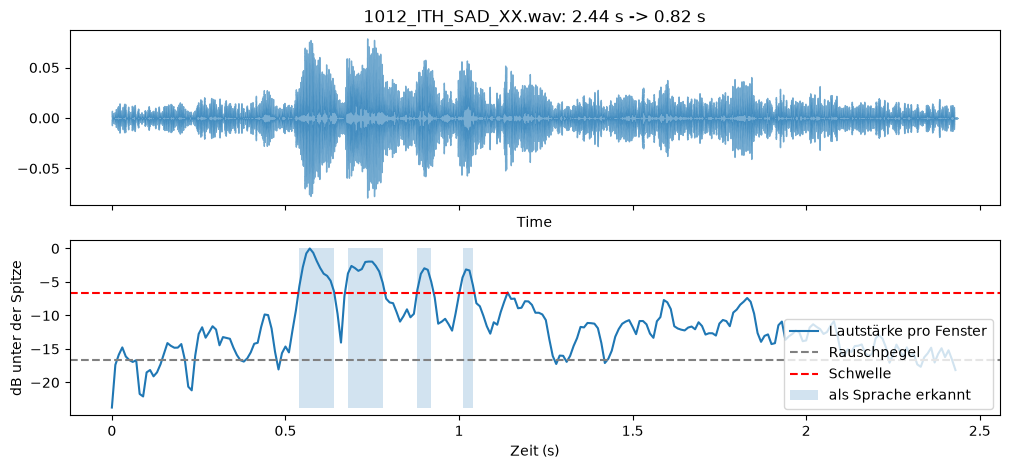

Original:


Gekürzt:


ITS


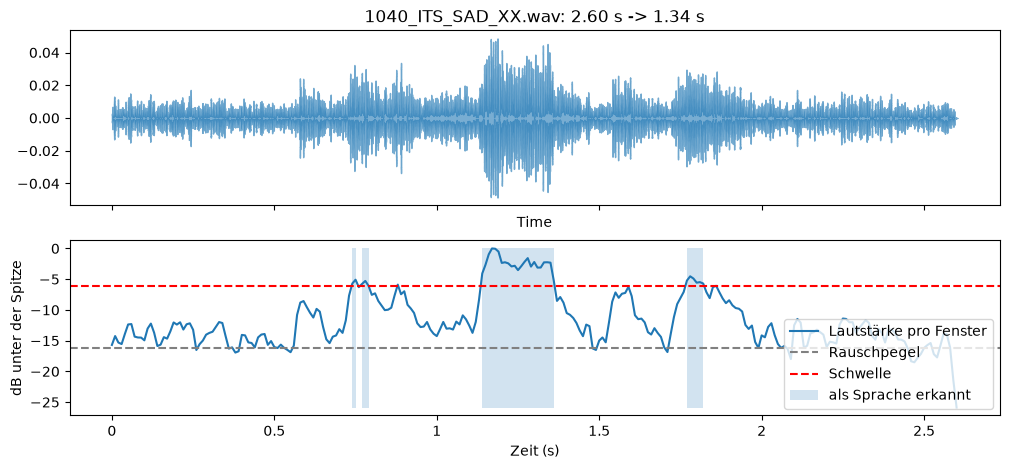

Original:


Gekürzt:


IWL


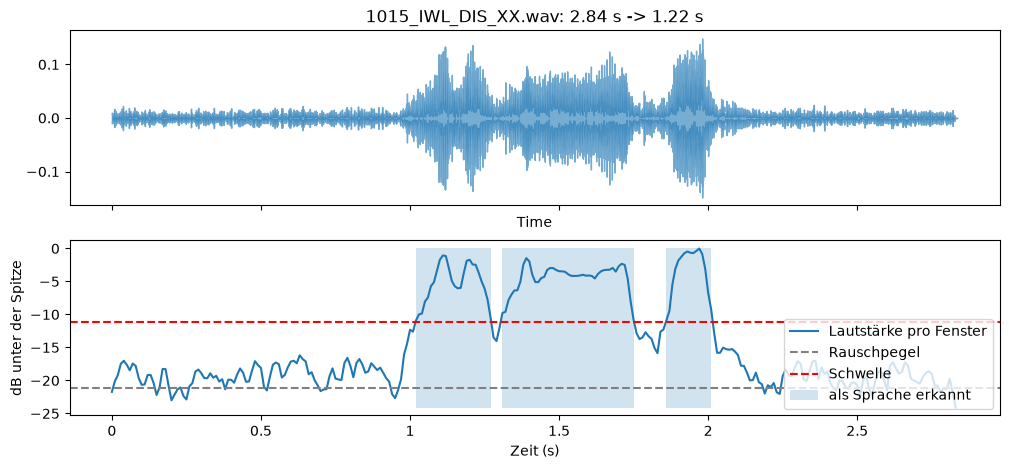

Original:


Gekürzt:


IWW


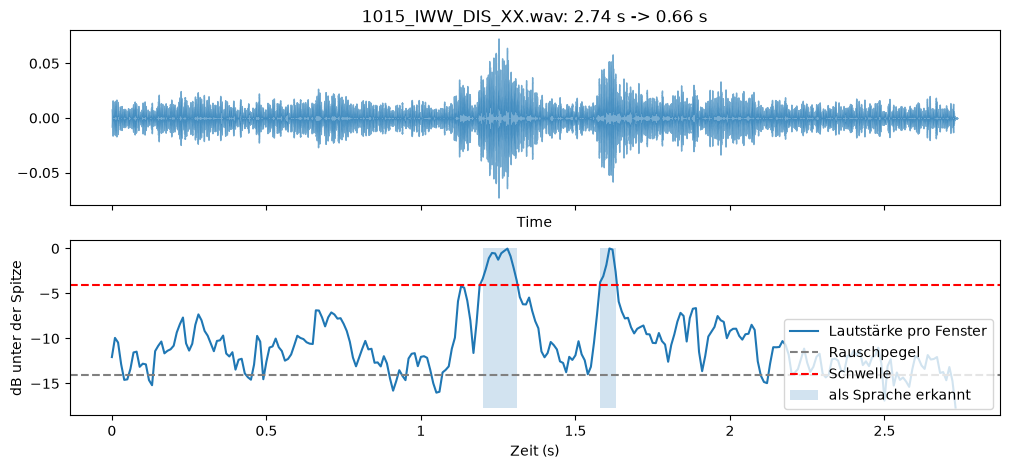

Original:


Gekürzt:


MTI


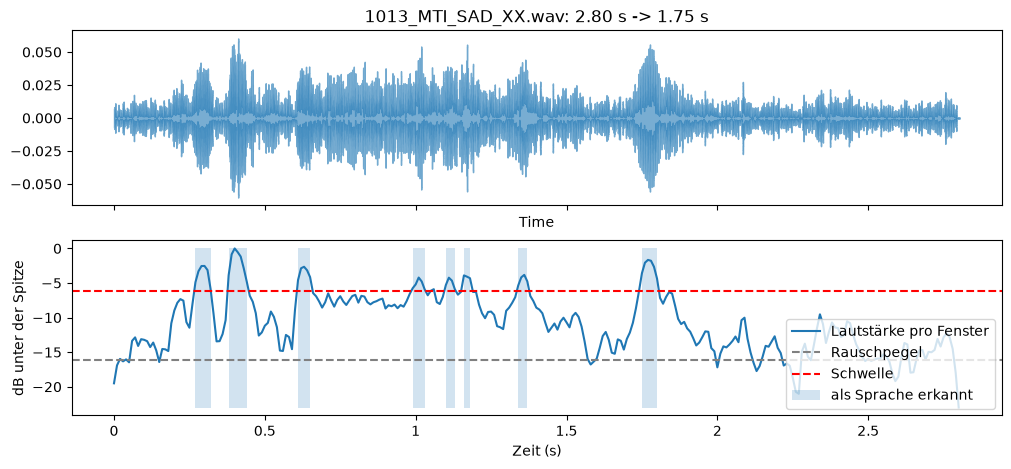

Original:


Gekürzt:


TAI


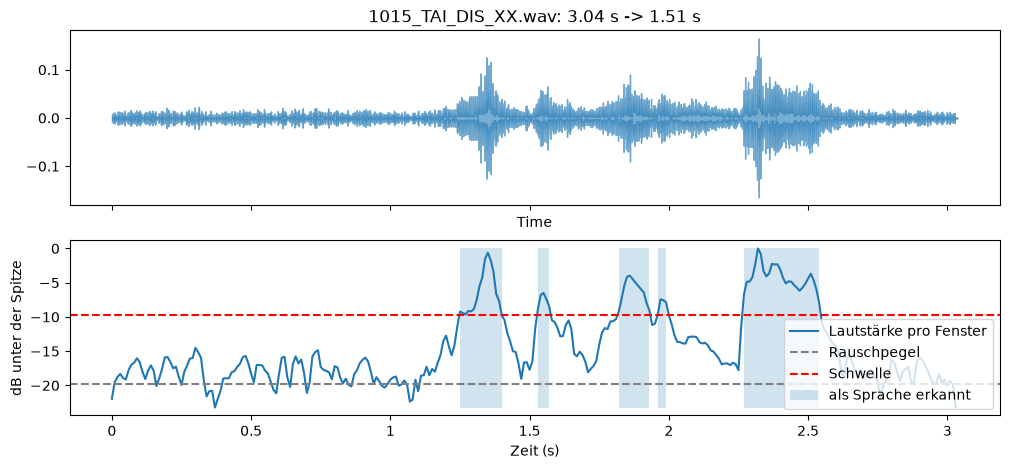

Original:


Gekürzt:


TIE


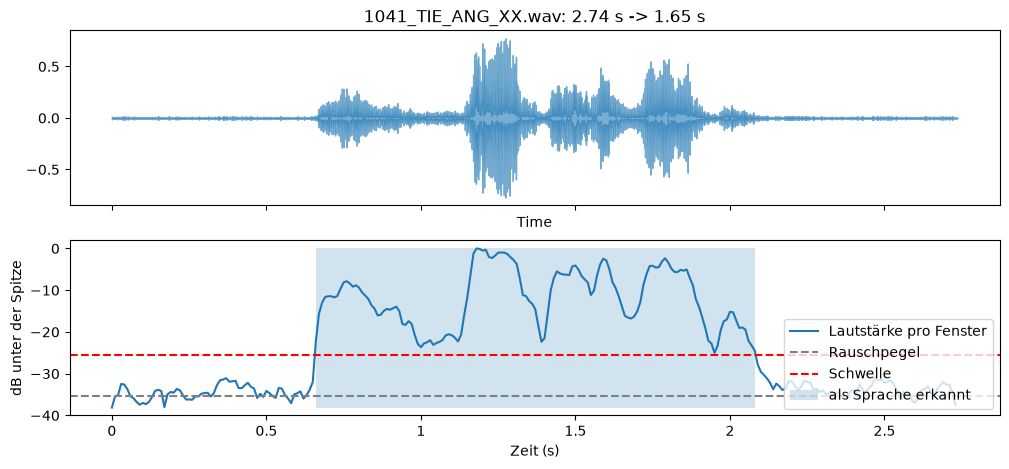

Original:


Gekürzt:


TSI


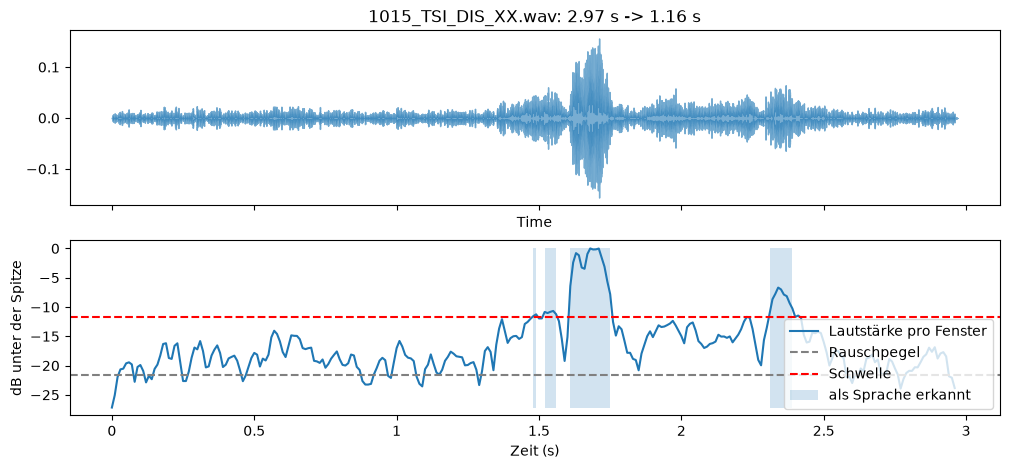

Original:


Gekürzt:


WSI


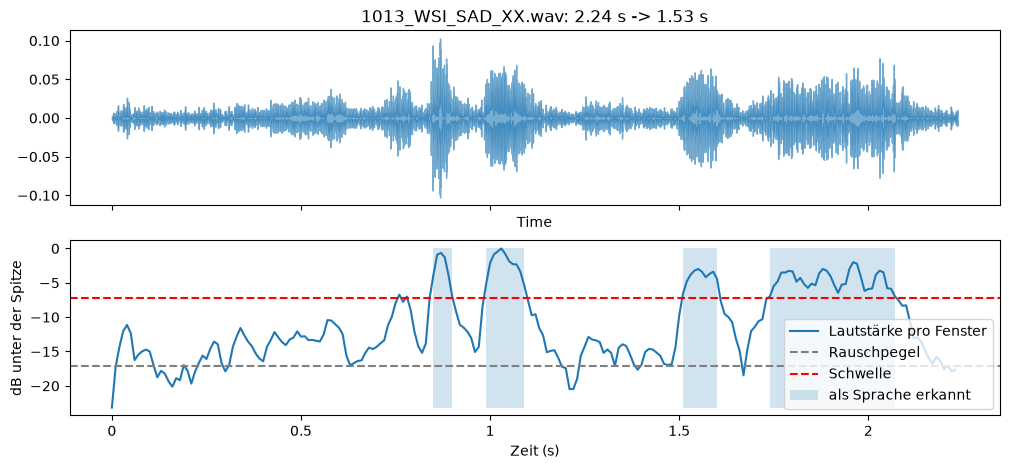

Original:


Gekürzt:


In [29]:
for sentence, group in df.groupby("sentence"):
    row = group.sample(1, random_state=0).iloc[0]
    print(sentence)
    show_trim(DATA_DIR / row["path"])

In [31]:
prepared = pd.read_csv(DATA_DIR / "cremad.csv")
prepared.head()

,path,speaker,sentence,emotion,intensity,duration,sample_rate,duration_trimmed,clipped_share,split
0,cremad/1001_DFA_ANG_XX.wav,1001,DFA,anger,XX,2.275562,16000,2.225563,0.0,val
1,cremad/1001_DFA_DIS_XX.wav,1001,DFA,disgust,XX,2.335688,16000,1.455000,0.0,val
2,cremad/1001_DFA_FEA_XX.wav,1001,DFA,fear,XX,2.168813,16000,1.435000,0.0,val
3,cremad/1001_DFA_HAP_XX.wav,1001,DFA,joy,XX,1.868500,16000,1.255000,0.0,val
4,cremad/1001_DFA_NEU_XX.wav,1001,DFA,neutral,XX,2.035375,16000,1.385000,0.0,val


<Axes: title={'center': 'Emotion Distribution'}, xlabel='emotion'>

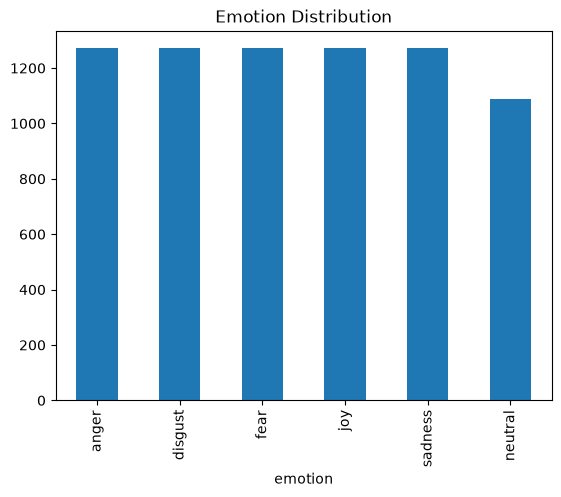

In [32]:
prepared.value_counts("emotion").plot(kind="bar", title="Emotion Distribution") 

<Axes: title={'center': 'Duration Distribution'}, xlabel='Duration ', ylabel='Count'>

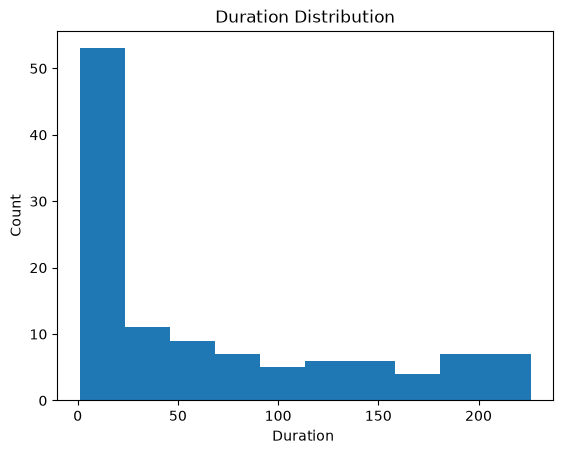

In [33]:
prepared.value_counts("duration").plot(kind="hist", title="Duration Distribution", xlabel="Duration ", ylabel="Count")  

<Axes: title={'center': 'Duration Distribution  '}, ylabel='Frequency'>

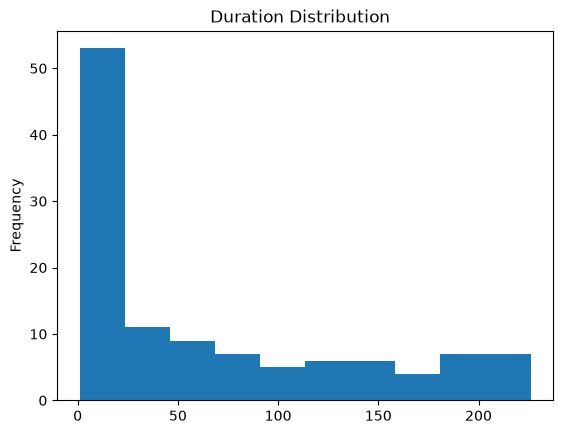

In [34]:
df.value_counts("duration").plot(kind="hist", title="Duration Distribution  ")

In [35]:
prepared["cut"] = prepared["duration"] - prepared["duration_trimmed"]
print(prepared[["duration", "duration_trimmed", "cut"]].describe())

          duration  duration_trimmed          cut
count  7442.000000       7442.000000  7442.000000
mean      2.542884          1.878580     0.664304
std       0.505979          0.455164     0.356227
min       1.267937          0.675000     0.000000
25%       2.202187          1.565000     0.410000
50%       2.502500          1.825000     0.627625
75%       2.836187          2.131937     0.874406
max       5.005000          4.535000     2.995750
